# Lab 5 - Logistic Regression and Binary Classification

## Predicting customer churn

In this lab we move from **regression**, where the target is continuous, to **binary classification**, where the target has two possible classes. We will build a logistic-regression classifier that estimates the probability that a telecommunications customer will leave.

The notebook follows the worked-example → guided-practice → independent-exercise structure used in earlier labs. It is designed to run in **Jupyter Notebook** or **Google Colab**.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Learning objectives

By the end of this lab you should be able to:

- identify the observation, features, target and positive class in a classification problem;
- inspect class balance before modelling;
- create a stratified train/test split;
- establish a majority-class baseline;
- preprocess numeric and categorical features without leaking test information;
- fit a logistic-regression classifier;
- distinguish predicted probabilities from predicted classes;
- interpret a confusion matrix;
- calculate and interpret accuracy, precision, recall and F1;
- explore how a decision threshold changes false positives and false negatives;
- discuss the practical and ethical consequences of classification errors;
- connect the classification workflow to the CA project.

## References

This lab is based principally on:

- Shah, C., *A Hands-On Introduction to Data Science with Python*, 2nd ed., Cambridge University Press, Chapter 8: **Supervised Learning**, especially the sections introducing logistic regression and classification.
- scikit-learn documentation for `LogisticRegression`, `DummyClassifier`, `ColumnTransformer`, `Pipeline` and classification metrics.

## The business question

A telecommunications company wants to identify customers who may leave its service. The target column is `Churn`:

- `Churn = Yes`: the customer left, represented as class **1**;
- `Churn = No`: the customer remained, represented as class **0**.

For this lab, **churn is the positive class**. This does not mean that churn is desirable. In classification, “positive” means the event of interest.

Before modelling, consider:

1. What could the company do with a churn-risk estimate?
2. What is the cost of incorrectly flagging a customer as likely to churn?
3. What is the cost of missing a customer who actually churns?
4. Should every available customer attribute be used simply because it improves performance?

## Import libraries

In [5]:
# data wrangling
import pandas as pd
import numpy as np

# visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# modelling and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

## Load the data

The code below reads the public customer-churn CSV directly. If the network is unavailable, download the CSV first and change `DATA_SOURCE` to the local filename.

In [8]:
DATA_SOURCE = "/content/drive/MyDrive/Telco-Customer-Churn.csv"
churn_data = pd.read_csv(DATA_SOURCE)
print("Shape:", churn_data.shape)
churn_data.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Inspect the data

In [9]:
churn_data.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [11]:
print("Columns:")
print(churn_data.columns.tolist())
print()
print("Data types:")
display(churn_data.dtypes.to_frame("dtype"))
print()
print("Missing values as read by pandas:")
display(churn_data.isna().sum().sort_values(ascending=False).head(10))

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values as read by pandas:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


### Important data-quality issue: `TotalCharges`

`TotalCharges` is read as text because some records contain blank strings. We will convert it to numeric. Invalid or blank entries become `NaN`, which will be imputed **inside the modelling pipeline using training data only**.

In [12]:
churn_data["TotalCharges"] = pd.to_numeric(
    churn_data["TotalCharges"], errors="coerce"
)

print("Missing TotalCharges after conversion:", churn_data["TotalCharges"].isna().sum())
churn_data[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T

Missing TotalCharges after conversion: 11


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


## Inspect the target and class balance

A classifier should not be fitted until we know how frequent each class is. A model that always predicts the majority class can achieve apparently reasonable accuracy without identifying any positive cases.

,count,percentage
Churn,,
No,5174,73.5
Yes,1869,26.5


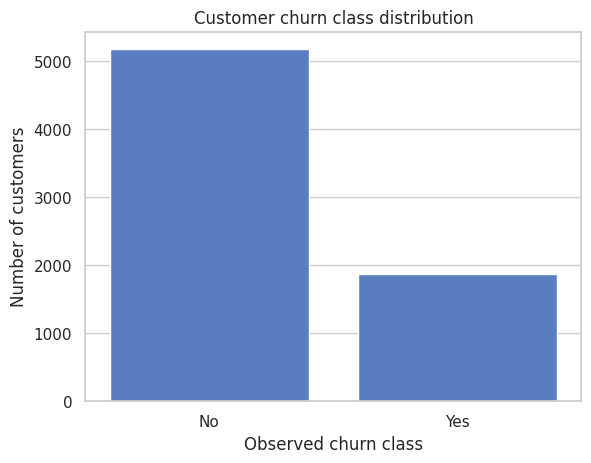

In [13]:
class_counts = churn_data["Churn"].value_counts()
class_percent = churn_data["Churn"].value_counts(normalize=True).mul(100).round(1)

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent,
})
display(class_summary)

ax = sns.countplot(data=churn_data, x="Churn")
ax.set_title("Customer churn class distribution")
ax.set_xlabel("Observed churn class")
ax.set_ylabel("Number of customers")
plt.show()

# <font color="red"><b>Exercise 1 - Understand the classification problem</b></font>

Answer in a Markdown cell:

1. What does one row represent?
2. What is the target?
3. Which class is the positive class?
4. Is the dataset balanced?
5. If a classifier predicts `No` for every customer, approximately what accuracy would it obtain?
6. Why would that classifier still be of limited value?

**Write your answers here:**

1. One customer
2. The target is Churn, whether the customer left the service.
3. The positive class is churn (Churn = Yes).
4. No, the dataset is imbalanced: about 73.5% of customers did not churn (5,174) and 26.5% did (1,869).
5. Predicting No for everyone would give roughly 73.5% accuracy.
6. That classifier never finds a single churner. Its recall for churn is 0, so it is useless for the business goal of spotting at-risk customers, even though its accuracy looks reasonable.

## Prepare the target and features

We encode `Yes` as 1 and `No` as 0. `customerID` is an identifier and should not be used as a predictor.

For the main worked model we also exclude `gender` and `SeniorCitizen`. These attributes may be useful for **auditing** model performance, but using personal or sensitive characteristics in an operational decision requires a clear justification, appropriate governance and an assessment of potential harm.

In [14]:
# Binary target: Yes -> 1, No -> 0
y = churn_data["Churn"].map({"No": 0, "Yes": 1})

# Preserve audit attributes separately before excluding them from the model
comparison_attributes = churn_data[["gender", "SeniorCitizen"]].copy()

# Exclude identifier, target and selected personal attributes
X = churn_data.drop(
    columns=["customerID", "Churn", "gender", "SeniorCitizen"]
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique()))

Feature matrix shape: (7043, 17)
Target shape: (7043,)
Target values: [np.int64(0), np.int64(1)]


## Create a stratified train/test split

`stratify=y` helps preserve approximately the same churn proportion in the training and test sets. The test set remains unseen during fitting.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_balance = pd.DataFrame({
    "complete_data": y.value_counts(normalize=True).sort_index(),
    "training_data": y_train.value_counts(normalize=True).sort_index(),
    "test_data": y_test.value_counts(normalize=True).sort_index(),
})
split_balance.index = ["No churn (0)", "Churn (1)"]
split_balance

,complete_data,training_data,test_data
No churn (0),0.73463,0.734647,0.734564
Churn (1),0.26537,0.265353,0.265436


# <font color="red"><b>Exercise 2 - Check the split</b></font>

1. Record the number of rows in the training and test sets.
2. Confirm that no row appears in both sets by checking their indices.
3. Explain why `stratify=y` is useful for this dataset.

In [19]:
# 1. Print the training and test row counts
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

# 2. Find the intersection of the training and test indices
overlap = X_train.index.intersection(X_test.index)
print("Rows appearing in both sets:", len(overlap))

# 3. Explain why `stratify=y` is useful for this dataset.
# Purpose of stratification: Only about 26.5% of customers churn, so a purely random split could leave the training or test set with noticeably more or fewer churners.

Training rows: 5634
Test rows: 1409
Rows appearing in both sets: 0


**Explain the purpose of stratification here:**



## Establish a baseline model

For classification, a simple baseline predicts the most frequent training class for every case. The fitted classifier should be compared with this reference.

In [22]:
baseline = DummyClassifier(strategy="most_frequent") #https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_results = {
    "accuracy": accuracy_score(y_test, baseline_pred),
    "precision": precision_score(y_test, baseline_pred, zero_division=0),
    "recall": recall_score(y_test, baseline_pred, zero_division=0),
    "f1": f1_score(y_test, baseline_pred, zero_division=0),
}

pd.Series(baseline_results, name="majority_class_baseline").round(3)

,majority_class_baseline
accuracy,0.735
precision,0.000
recall,0.000
f1,0.000


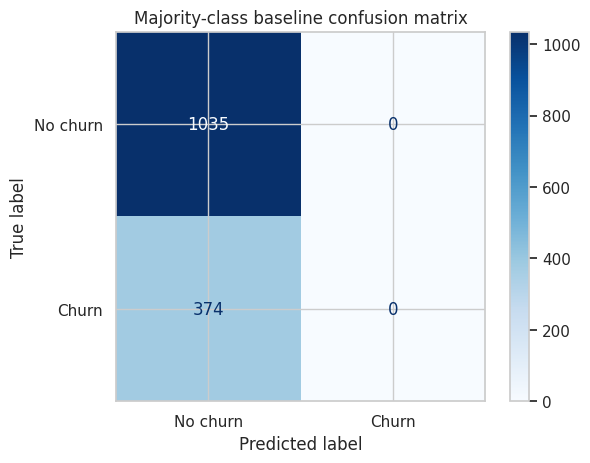

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["No churn", "Churn"],
    cmap="Blues",
)
plt.title("Majority-class baseline confusion matrix")
plt.show()

### Baseline interpretation

The majority baseline can have moderate or high accuracy because most customers do not churn. However, its recall and F1 score for churn are zero because it never predicts the positive class.

This demonstrates why **accuracy alone is insufficient** for an imbalanced classification problem.

## Build a leakage-safe preprocessing and modelling pipeline

The dataset contains numeric and categorical features. We will:

- impute numeric missing values using the training median;
- standardise numeric features;
- impute missing categorical values using the most frequent training category;
- one-hot encode categorical features;
- fit logistic regression.

Because these steps are contained in a pipeline, their fitted values are learned from the training data and then applied to the test data.

In [24]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## What is a scikit-learn pipeline?

A **pipeline** connects the data-preparation steps and the machine-learning model into one organised workflow.

In this lab, the pipeline performs the following sequence:

1. Missing numeric values are replaced using the median.
2. Numeric features are standardised.
3. Missing categorical values are replaced using the most frequent category.
4. Categorical features are converted into numeric columns using one-hot encoding.
5. Logistic regression is fitted using the prepared features.

When we call:

```python
logistic_model.fit(X_train, y_train)
```

the pipeline learns the required preparation values from the **training data** and then fits the logistic-regression model.

When we later call:

```python
logistic_model.predict(X_test)
```

the pipeline automatically applies the same preparation steps.

In [26]:
# https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

logistic_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

## Fit logistic regression

`fit()` estimates the logistic-regression coefficients from the training observations. The test target is not supplied during fitting.

In [27]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

## Predicted classes and predicted probabilities

`predict()` returns class labels. `predict_proba()` returns one probability for each class. Column 1 contains the predicted probability of churn because churn is encoded as class 1.

In [28]:
test_pred = logistic_model.predict(X_test)
test_prob = logistic_model.predict_proba(X_test)[:, 1]

prediction_preview = pd.DataFrame({
    "actual_class": y_test,
    "predicted_probability_of_churn": test_prob,
    "predicted_class_at_0.50": test_pred,
}, index=X_test.index)

prediction_preview.head(10).round(3)

,actual_class,predicted_probability_of_churn,predicted_class_at_0.50
437,0,0.044,0
2280,0,0.662,1
2235,0,0.060,0
4460,0,0.410,0
3761,0,0.022,0
5748,0,0.616,1
3568,0,0.460,0
2976,0,0.128,0
5928,0,0.003,0
1639,1,0.364,0


# <font color="red"><b>Exercise 3 - Interpret probabilities and classes</b></font>

Using the preview above:

**1. Find a customer with a churn probability below 0.50.**

Customer 437 of 0.044

**2. Find a customer with a churn probability above or equal to 0.50.**

Customer 2280 of 0.662

**3. Explain why probability and predicted class are not the same quantity.**

A probability is the models estimated likelihood of churn, a continuous value between 0 and 1.

The predicted class is a hard yes/no decision made by comparing that probability to a threshold (0.50 by default).

Two customers with probabilities of 0.51 and 0.99 get the same class even though the model is far more confident about one of them, and changing the threshold changes the class without changing the probability.

**4. Identify one incorrect prediction and state whether it is a false positive or false negative.**

Customer 1639 actually churned (1), but its probability of 0.364 gives a predicted class of 0. That is a false negative.

Customer 2280 did not churn (0) but was predicted to churn (0.662). That is a false positive.

## Evaluate the logistic-regression classifier

In [36]:
logistic_results = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
}

comparison = pd.DataFrame({
    "Majority baseline": baseline_results,
    "Logistic regression": logistic_results,
}).T
comparison.round(3)

,accuracy,precision,recall,f1
Majority baseline,0.735,0.000,0.000,0.000
Logistic regression,0.801,0.648,0.551,0.595


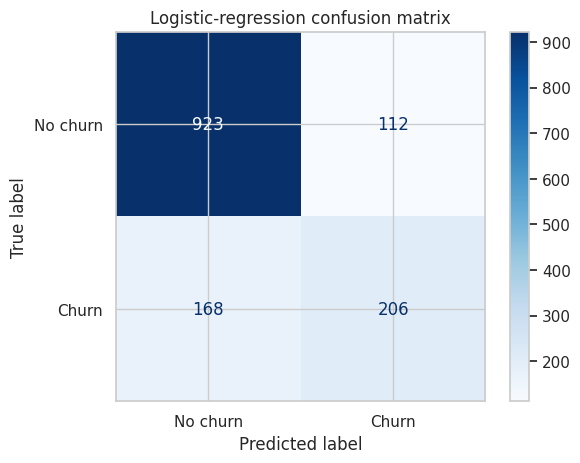

In [37]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No churn", "Churn"],
    cmap="Blues",
)
plt.title("Logistic-regression confusion matrix")
plt.show()

In [38]:
print(classification_report(
    y_test,
    test_pred,
    target_names=["No churn", "Churn"],
    digits=3,
))

              precision    recall  f1-score   support

    No churn      0.846     0.892     0.868      1035
       Churn      0.648     0.551     0.595       374

    accuracy                          0.801      1409
   macro avg      0.747     0.721     0.732      1409
weighted avg      0.793     0.801     0.796      1409



## Reading the confusion matrix

With churn as the positive class:

- **True negative:** correctly predicts that a customer remains.
- **False positive:** predicts churn, but the customer remains.
- **False negative:** predicts no churn, but the customer leaves.
- **True positive:** correctly predicts that a customer churns.

The metrics answer different questions:

- **Accuracy:** What proportion of all predictions are correct?
- **Precision:** When the model predicts churn, how often is it correct?
- **Recall:** Of all customers who churned, how many did the model identify?
- **F1:** What is the harmonic balance between precision and recall?

# <font color="red"><b>Exercise 4 - Calculate metrics from the confusion matrix</b></font>

Use `confusion_matrix(y_test, test_pred).ravel()` to obtain `tn`, `fp`, `fn`, and `tp`.

Then calculate accuracy, precision, recall and F1 **manually from the counts**. Compare your answers with scikit-learn's results.

In [41]:
# Extract the four confusion-matrix counts
# tn, fp, fn, tp = ...
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

# Calculate the four metrics from the counts
  # manual_accuracy = ...
manual_accuracy = (tp + tn) / (tp + tn + fp + fn)


  # manual_precision = ...
manual_precision = tp / (tp + fp)

  # manual_recall = ...
manual_recall = tp / (tp + fn)

  # manual_f1 = ...
manual_f1 = 2 * manual_precision * manual_recall / (manual_precision + manual_recall)


# Display your results
# pd.Series({...}).round(3)
pd.Series({
    "accuracy": manual_accuracy,
    "precision": manual_precision,
    "recall": manual_recall,
    "f1": manual_f1,
}).round(3)

TN: 923 FP: 112 FN: 168 TP: 206


,0
accuracy,0.801
precision,0.648
recall,0.551
f1,0.595


## Explore decision thresholds

The default threshold is 0.50, but it is not a universal rule. Lowering the threshold normally predicts more positive cases, which may increase recall and false positives. Raising it normally predicts fewer positive cases, which may increase precision but also increase false negatives.

In [42]:
def metrics_at_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "false_positives": fp,
        "false_negatives": fn,
        "predicted_churn": int(predictions.sum()),
    }

threshold_results = pd.DataFrame([
    metrics_at_threshold(y_test, test_prob, threshold)
    for threshold in [0.30, 0.50, 0.70]
])
threshold_results.round(3)

,threshold,accuracy,precision,recall,f1,false_positives,false_negatives,predicted_churn
0,0.3,0.747,0.516,0.743,0.609,261,96,539
1,0.5,0.801,0.648,0.551,0.595,112,168,318
2,0.7,0.766,0.739,0.182,0.292,24,306,92


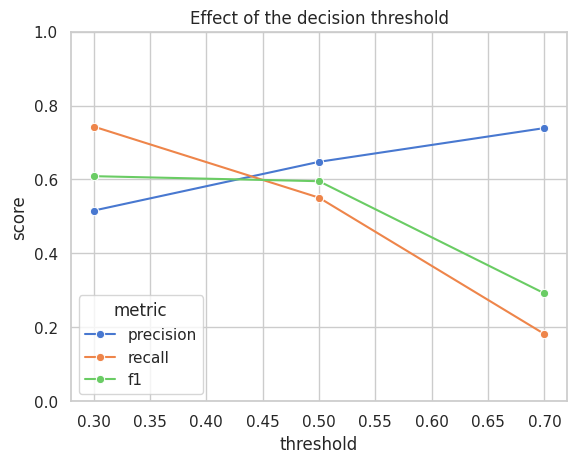

In [43]:
threshold_long = threshold_results.melt(
    id_vars="threshold",
    value_vars=["precision", "recall", "f1"],
    var_name="metric",
    value_name="score",
)

sns.lineplot(
    data=threshold_long,
    x="threshold",
    y="score",
    hue="metric",
    marker="o",
)
plt.ylim(0, 1)
plt.title("Effect of the decision threshold")
plt.show()

# <font color="red"><b>Exercise 5 - Threshold decision</b></font>

Answer in a Markdown cell:

1. What happens to recall as the threshold increases?
2. What happens to the number of false negatives?
3. What happens to the number of customers flagged as likely to churn?
4. If missing a customer who will leave is especially costly, which of the three thresholds is the strongest starting candidate?
5. Why should the company not select a threshold using metrics alone?

**Write your answers here:**

1. Recall falls as the threshold rises
2. False negatives increase
3. The number of customers flagged as likely to churn drops
4. If missing a churner is especially costly, 0.30 is the strongest starting candidate. It has the highest recall and the fewest false negatives, and it also has the best F1 (0.609).
5. Metrics alone ignore the real-world costs and constraints:
  - how much a retention contact or offer costs;
  - how much a retained customer is worth;
  - how many customers the retention team can actually handle;
  - the effect on customers who are wrongly flagged.

## Inspect the fitted logistic-regression coefficients

A positive coefficient increases the model's log-odds of churn, while a negative coefficient decreases them, holding the other encoded features constant. Coefficient size is affected by scaling and encoding, and coefficients do **not** establish causation.

In [47]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = logistic_model.named_steps["classifier"].coef_[0]

coefficient_table = (
    pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
    .assign(abs_coefficient=lambda df: df["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
)

coefficient_table.head(15)

,feature,coefficient,abs_coefficient
0,numeric__tenure,-1.218822,1.218822
35,categorical__Contract_Two year,-0.797890,0.797890
12,categorical__InternetService_DSL,-0.665196,0.665196
13,categorical__InternetService_Fiber optic,0.635186,0.635186
33,categorical__Contract_Month-to-month,0.582763,0.582763
1,numeric__MonthlyCharges,-0.581843,0.581843
2,numeric__TotalCharges,0.500732,0.500732
36,categorical__PaperlessBilling_No,-0.356920,0.356920
22,categorical__DeviceProtection_No internet service,-0.307633,0.307633
16,categorical__OnlineSecurity_No internet service,-0.307633,0.307633


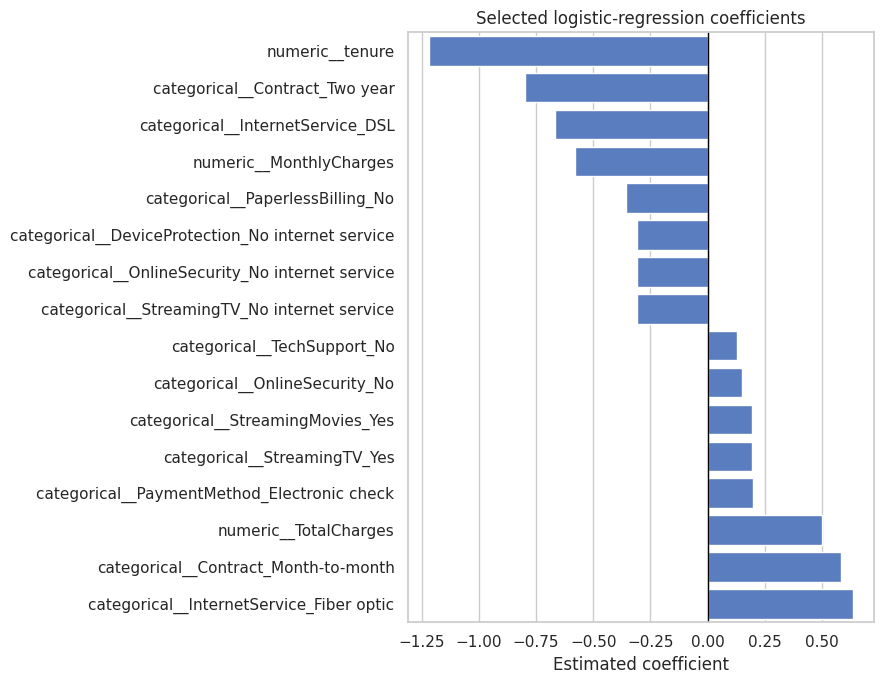

In [48]:
top_coefficients = pd.concat([
    coefficient_table.nsmallest(8, "coefficient"),
    coefficient_table.nlargest(8, "coefficient"),
]).sort_values("coefficient")

plt.figure(figsize=(9, 7))
sns.barplot(data=top_coefficients, x="coefficient", y="feature")
plt.axvline(0, color="black", linewidth=1)
plt.title("Selected logistic-regression coefficients")
plt.xlabel("Estimated coefficient")
plt.ylabel("")
plt.tight_layout()
plt.show()

# <font color="red"><b>Exercise 6 - Interpret cautiously</b></font>

Choose:

- one feature with a positive coefficient; and
- one feature with a negative coefficient.

For each feature, write a cautious interpretation. Use wording such as **“is associated with a higher/lower predicted probability of churn, holding other included features constant.”**

Do not use causal wording such as *causes customers to churn*.

**Write your interpretations here:**

- **Positive coefficient:** InternetService_Fiber optic (+0.635). Having fibre optic internet service is associated with a higher predicted probability of churn, holding the other included features constant.

- **Negative coefficient:** tenure (−1.219). A longer tenure is associated with a lower predicted probability of churn, holding the other included features constant. Because tenure is standardised, this is the effect of a one-standard-deviation increase.


## Responsible classification check

A classifier can influence which customers receive attention, incentives or scrutiny. Before operational use, the organisation should consider:

- whether the data were collected for this purpose;
- whether sensitive attributes or proxies are present;
- whether error rates differ across relevant groups;
- whether interventions could disadvantage customers;
- whether a customer can challenge or correct inaccurate information;
- whether a human reviews consequential decisions;
- how model performance and data drift will be monitored.

The model in this lab is an educational example and should not be treated as deployment-ready.

# <font color="red"><b>Exercise 7 - Ethics and error consequences</b></font>

Answer in a Markdown cell:

1. Give one plausible consequence of a false positive.
2. Give one plausible consequence of a false negative.
3. Why were `gender` and `SeniorCitizen` excluded from the main model?
4. Could excluding them guarantee that the model is fair? Explain.
5. What additional evidence would be required before using this model operationally?

**Write your answers here:**

**1. False positive:** a loyal customer receives retention calls or discount offers they didnt need. This wastes budget, and the unnecessary contact could annoy them or erode trust.

**2. False negative:** a customer who is about to leave gets no intervention, so the company loses their future revenue without ever having had a chance to keep them.

**3.Excluded:** ```gender``` and ```SeniorCitizen``` are personal or sensitive characteristics. Using them in an operational decision would need a clear justification and governance, and could lead to unfair or discriminatory treatment. They are kept aside so they can be used for auditing the model instead.

**4.Explain:** Excluding them does not guarantee fairness. Fairness has to be checked by comparing error rates such as recall and false positives across groups, not assumed.


**5.Additional Evidence:**
Before operational use, the company would need:
- an error audit
- validation on more recent data, and ideally cross-validation
- evidence that the retention interventions actually work
- human review of consequential decisions
- a way for customers to challenge outcomes

# <font color="red"><b>Independent challenge - Improve the analysis, not just the score</b></font>

Complete **one** of the following:

### **Option A: Audit performance by an excluded attribute**

Join the test indices back to `gender` or `SeniorCitizen` and compare recall and false-positive counts between groups. Be careful with small groups and avoid claiming that one metric proves fairness.

<br>

### **Option B: Develop a simple feature**

Create one defensible feature, such as average charges per month of tenure, avoiding division by zero. Refit the pipeline and compare results with the original model.

<br>

### **Option C: Compare threshold policies**

Assume that contacting one customer costs €5 and successfully retaining a correctly identified churner is worth €60. Define a simple value calculation using TP and FP counts. Compare the three thresholds and explain the assumptions and limitations.

<br>

**Document:**

1. what you changed;
2. why the change is relevant;
3. the evidence produced;
4. whether the change is practically meaningful;
5. one limitation.

In [51]:
# Write your independent challenge code here
# OPTION C: COMPARE THRESHOLD POLICIES

CONTACT_COST = 5
RETENTION_VALUE = 60

value_rows = []
for threshold in [0.30, 0.50, 0.70]:
    preds = (test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    contacted = tp + fp
    value = RETENTION_VALUE * tp - CONTACT_COST * contacted
    value_rows.append({
        "threshold": threshold, "TP": tp, "FP": fp,
        "contacted": contacted, "net_value_eur": value,
    })

pd.DataFrame(value_rows)

,threshold,TP,FP,contacted,net_value_eur
0,0.3,278,261,539,13985
1,0.5,206,112,318,10770
2,0.7,68,24,92,3620


**Write your evaluation here:**

**1. what you changed**

the thresholds were compared on estimated business value rather than on F1 alone.

<br>

**2. why the change is relevant**

in this problem, a missed churner (worth €60) costs far more than an unnecessary contact (€5). Business value captures that asymmetry, which F1 does not.

<br>

**3. the evidence produced**

the 0.30 threshold gives the highest net value, about €3,200 more than the default 0.50, even though it produces 261 false positives.

<br>

**4. whether the change is practically meaningful**

yes, the difference is meaningful. This analysis supports lowering the threshold below 0.50.

<br>

**5. one limitation**

It assumes every correctly identified churner is retained, which is unrealistic. A retention success rate should be included.


# <font color="red"><b>CA Transfer Task</b></font>

Complete this table for your own proposed CA investigation.

| Question | Your response |
|---|---|
| What is the unit of analysis? | |
| Is the target continuous, binary categorical or multiclass categorical? | |
| If classification, what is the positive class? | |
| What simple baseline is appropriate? | |
| Which error is most consequential? | |
| Which evaluation metric should receive greatest attention? | |
| Is class imbalance likely? |  |
| Which features may create leakage? |  |
| Which attributes may require an ethical justification or subgroup audit? |  |
| What evidence would demonstrate useful generalisation? |  |

## Lab summary

In this lab you:

- moved from a continuous regression target to a binary classification target;
- inspected class balance;
- used a stratified train/test split;
- established a majority-class baseline;
- created a leakage-safe preprocessing pipeline;
- fitted logistic regression;
- interpreted probabilities, classes and coefficients;
- evaluated predictions using a confusion matrix, accuracy, precision, recall and F1;
- investigated decision thresholds;
- considered the consequences and ethical implications of classification errors.

### Before leaving

Save or download your completed notebook. In Colab use **File → Download → Download .ipynb**.